# Dự đoán Giá Xe Máy Cũ
**Quy trình End-to-End:**

1. Đọc dữ liệu
2. EDA
3. Làm sạch nhiễu (8 bước)
4. Feature Engineering
5. Huấn luyện & So sánh 4 Model
6. Thí nghiệm A/B Trước & Sau làm sạch
7. Phân tích lỗi & Đóng gói `models/model.pkl`.

In [1]:
import io
import os
import re
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.base import clone

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: '%.2f' % x)
print(f"scikit-learn version: {sklearn.__version__}")

scikit-learn version: 1.6.1


## 1. Đọc Dữ Liệu & Khám Phá Sơ Bộ (Initial Exploration)

In [2]:
POSSIBLE_PATHS = [
    'data/raw/chotot_xemay_named.csv',
    '../data/raw/chotot_xemay_named.csv',
    'chotot_xemay_named.csv'
]

file_path = next((p for p in POSSIBLE_PATHS if os.path.exists(p)), None)

if file_path is not None:
    df = pd.read_csv(file_path)
    print(f"Đã đọc file từ đường dẫn cục bộ: {file_path}")
else:
    from google.colab import files
    uploaded = files.upload()
    file_name = next(iter(uploaded))
    df = pd.read_csv(io.BytesIO(uploaded[file_name]))
    print(f"Đã đọc file tải lên: {file_name}")

print(f"Kích thước dữ liệu thô: {df.shape[0]:,} dòng x {df.shape[1]} cột")
df.head()

Đã đọc file từ đường dẫn cục bộ: chotot_xemay_named.csv
Kích thước dữ liệu thô: 30,563 dòng x 30 cột


,list_id,subject,body,price,price_string,regdate,mileage_v2,motorbikebrand,motorbikemodel,motorbiketype,motorbikecapacity,motorbikeorigin,condition_ad,condition_ad_name,region_v2,region_name,area_v2,area_name,ward_name,type,is_price_not_valid,number_of_images,list_time,orig_list_time,crawl_date,brand_name,model_name,type_name,capacity_name,origin_name
0,135045712,"Honda SH 125cc biển Thần Tài 39.79 đẹp,êm du","SH 125cc biển đẹp Thần Tài. Nguyên bản,.giấy...",33000000,33.000.000 đ,2013,15000.00,1,19,1,3.00,NaN,1,Đã sử dụng,1001,Bắc Ninh,100101,Thành phố Bắc Ninh,Phường Đại Phúc,s,False,6,1791057503000,NaN,2026-10-05,Honda,SH,Tay ga,100 - 175 cc,NaN
1,135027442,Honda SH 150 ABS 2020 Trắng 39000 km,SH 2020 150 ABS odo 3v9 ngon không có gì bàn c...,68888888,68.888.888 đ,2020,39000.00,1,19,1,3.00,NaN,1,Đã sử dụng,1001,Bắc Ninh,100105,Thị xã Từ Sơn,Phường Đình Bảng,s,False,3,1791011704168,1790959437000.00,2026-10-05,Honda,SH,Tay ga,100 - 175 cc,NaN
2,135024495,Honda Cub Cổ điển Trắng xanh,"Xe máy Honda Cub trắng xanh, kiểu dáng cổ điển...",5000000,5.000.000 đ,1999,150000.00,1,10,2,5.00,NaN,1,Đã sử dụng,1001,Bắc Ninh,100102,Huyện Yên Phong,Xã Long Châu,s,False,9,1790943110000,NaN,2026-10-05,Honda,Cub,Xe số,Không biết rõ,NaN
3,134916468,Yamaha R15 V3 Xanh lá Nhập khẩu,"Xe côn tay Yamaha R15 V3 màu xanh lá, kiểu dán...",26500000,26.500.000 đ,2019,10116.00,2,38,3,3.00,7.00,1,Đã sử dụng,1001,Bắc Ninh,100105,Thị xã Từ Sơn,Xã Phù Chẩn,s,False,1,1790474382000,NaN,2026-10-05,Yamaha,Dòng khác,Tay côn/Moto,100 - 175 cc,Nước khác
4,134915720,Suzuki Hayate 125 Đen,"hayate 125 máy zin chất , khoẻ\ngiấy tờ đầy đủ...",2500000,2.500.000 đ,2015,16137.00,4,57,1,3.00,NaN,1,Đã sử dụng,1001,Bắc Ninh,100108,Huyện Lương Tài,Xã An Thịnh,s,False,1,1790471628000,NaN,2026-10-05,Suzuki,Hayate,Tay ga,100 - 175 cc,NaN


In [3]:
# Lưu bản gốc tuyệt đối để đối chiếu
df_raw = df.copy()

print("--- Thông tin cột ---")
df.info()

missing = (df.isna().mean() * 100).round(2).sort_values(ascending=False)
print("\n--- Tỉ lệ thiếu (%) ---")
print(missing[missing > 0])

print("\n--- Thống kê cột số ---")
display(df.describe().T)

print(f"\nSố dòng trùng hoàn toàn: {df.duplicated().sum():,}")
print(f"Số list_id trùng: {df['list_id'].duplicated().sum():,}")

--- Thông tin cột ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30563 entries, 0 to 30562
Data columns (total 30 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   list_id             30563 non-null  int64  
 1   subject             30563 non-null  object 
 2   body                30563 non-null  object 
 3   price               30563 non-null  int64  
 4   price_string        30563 non-null  object 
 5   regdate             30563 non-null  int64  
 6   mileage_v2          30128 non-null  float64
 7   motorbikebrand      30563 non-null  int64  
 8   motorbikemodel      30563 non-null  int64  
 9   motorbiketype       30563 non-null  int64  
 10  motorbikecapacity   14982 non-null  float64
 11  motorbikeorigin     12809 non-null  float64
 12  condition_ad        30563 non-null  int64  
 13  condition_ad_name   30563 non-null  object 
 14  region_v2           30563 non-null  int64  
 15  region_name         30563 non-n

,count,mean,std,min,25%,50%,75%,max
list_id,30563.00,133627856.31,4556932.82,47654211.00,134135346.50,134547104.00,134862484.50,135079059.00
price,30563.00,29923852.68,102141183.97,0.00,10500000.00,19000000.00,34500000.00,13000000800.00
regdate,30563.00,2016.55,21.22,0.00,2013.00,2018.00,2022.00,2026.00
mileage_v2,30128.00,35767.80,97832.02,0.00,3849.50,15000.00,30000.00,1000000.00
motorbikebrand,30563.00,5.79,13.68,1.00,1.00,1.00,2.00,85.00
motorbikemodel,30563.00,132.41,184.30,0.00,19.00,25.00,279.00,906.00
motorbiketype,30563.00,1.72,0.91,1.00,1.00,1.00,2.00,4.00
motorbikecapacity,14982.00,2.84,0.75,0.00,3.00,3.00,3.00,5.00
motorbikeorigin,12809.00,3.22,2.55,1.00,1.00,1.00,5.00,10.00
condition_ad,30563.00,1.02,0.12,1.00,1.00,1.00,1.00,2.00



Số dòng trùng hoàn toàn: 0
Số list_id trùng: 0


In [4]:
for col in ['condition_ad_name', 'type', 'is_price_not_valid',
            'brand_name', 'type_name', 'capacity_name', 'origin_name']:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(10))

print(f"\nSố dòng xe khác nhau: {df['model_name'].nunique()}")
print(f"Số tin 'Dòng khác': {(df['model_name'] == 'Dòng khác').sum():,}")


--- condition_ad_name ---
condition_ad_name
Đã sử dụng    30101
Mới             462
Name: count, dtype: int64

--- type ---
type
s    30563
Name: count, dtype: int64

--- is_price_not_valid ---
is_price_not_valid
False    30416
NaN        147
Name: count, dtype: int64

--- brand_name ---
brand_name
Honda       18565
Yamaha       5326
Piaggio      1690
Suzuki        882
VinFast       764
SYM           761
Kymco         259
Kawasaki      212
Detech        188
GPX           161
Name: count, dtype: int64

--- type_name ---
type_name
Tay ga          16664
Xe số            7050
Tay côn/Moto     5493
Xe máy điện      1356
Name: count, dtype: int64

--- capacity_name ---
capacity_name
NaN              15584
100 - 175 cc     11750
Dưới 50 cc        1502
Trên 175 cc        697
50 - 100 cc        690
Không biết rõ      340
Name: count, dtype: int64

--- origin_name ---
origin_name
NaN           17754
Việt Nam       6654
Nhật Bản       2758
Nước khác      1586
Thái Lan        960
Đài Loan        

## 2. Phân Tích Khám Phá Dữ Liệu (EDA)
1. **Tình trạng xe (`condition_ad_name`):** Có 462 tin xe mới, cần lọc chỉ giữ `Đã sử dụng`.
2. **Cờ giá (`is_price_not_valid`) và Giá (`price`):** Cờ có giá trị thiếu và chưa bắt hết giá ảo (từ 0đ đến 13 tỷ VNĐ). Cần kết hợp lọc ngưỡng vật lý `[2 triệu, 500 triệu]` và IQR theo dòng xe.
3. **Biến mục tiêu lệch phải:** Cần áp dụng `np.log1p(price)` khi huấn luyện.

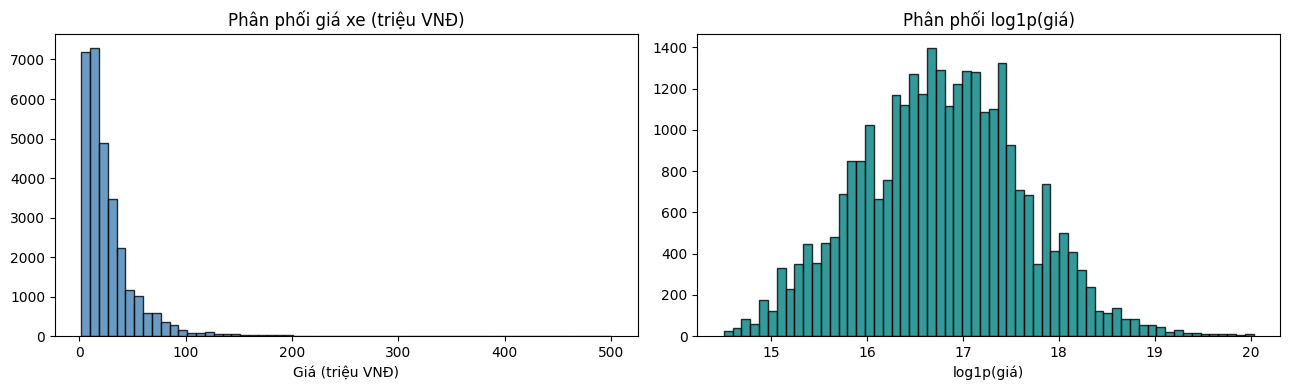

Độ lệch (skew) trước log: 5.19
Độ lệch (skew) sau log:   0.11


In [5]:
d = df[(df['condition_ad_name'] == 'Đã sử dụng') & (df['price'].between(2e6, 500e6))].copy()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(d['price'] / 1e6, bins=60, color='steelblue', edgecolor='black', alpha=0.8)
ax[0].set_title('Phân phối giá xe (triệu VNĐ)')
ax[0].set_xlabel('Giá (triệu VNĐ)')

ax[1].hist(np.log1p(d['price']), bins=60, color='teal', edgecolor='black', alpha=0.8)
ax[1].set_title('Phân phối log1p(giá)')
ax[1].set_xlabel('log1p(giá)')
plt.tight_layout()
plt.show()

print(f"Độ lệch (skew) trước log: {d['price'].skew():.2f}")
print(f"Độ lệch (skew) sau log:   {np.log1p(d['price']).skew():.2f}")

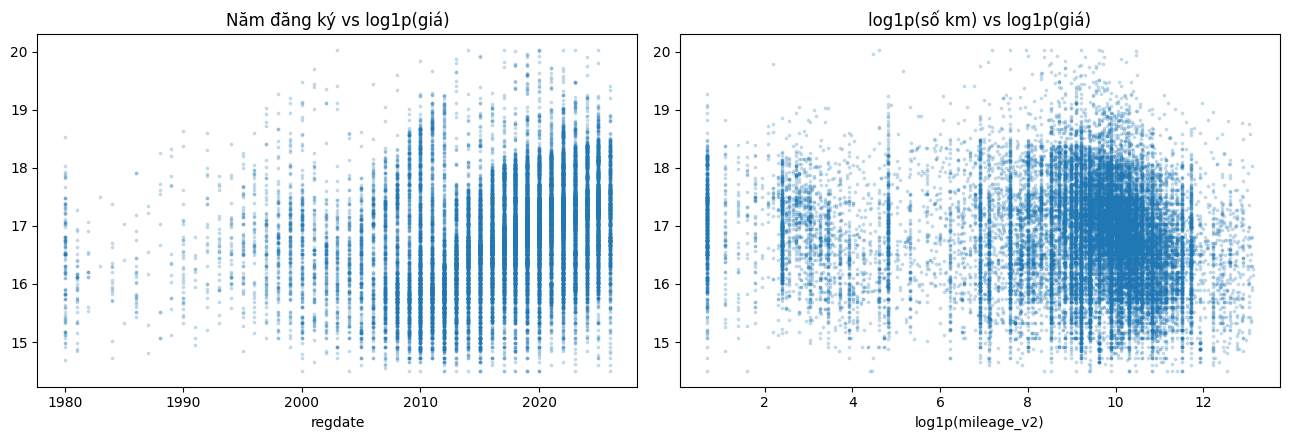

Tương quan Pearson với log1p(giá):
  regdate:    0.310
  mileage_v2: -0.140


In [6]:
v = d[(d['regdate'] >= 1980) & (d['mileage_v2'] > 0) & (d['mileage_v2'] < 500000)]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(v['regdate'], np.log1p(v['price']), s=3, alpha=0.2)
ax[0].set_title('Năm đăng ký vs log1p(giá)')
ax[0].set_xlabel('regdate')

ax[1].scatter(np.log1p(v['mileage_v2']), np.log1p(v['price']), s=3, alpha=0.2)
ax[1].set_title('log1p(số km) vs log1p(giá)')
ax[1].set_xlabel('log1p(mileage_v2)')
plt.tight_layout()
plt.show()

print("Tương quan Pearson với log1p(giá):")
print(f"  regdate:    {v['regdate'].corr(np.log1p(v['price'])):.3f}")
print(f"  mileage_v2: {v['mileage_v2'].corr(np.log1p(v['price'])):.3f}")

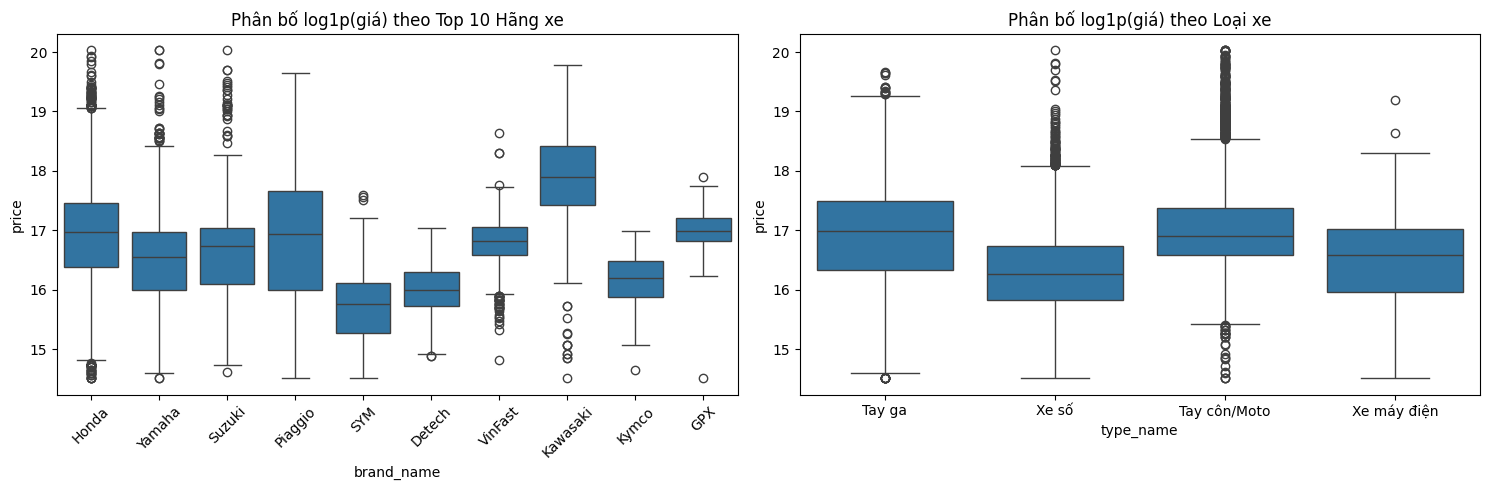

In [7]:
top_brands = d['brand_name'].value_counts().head(10).index
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=d[d['brand_name'].isin(top_brands)], x='brand_name', y=np.log1p(d['price']), ax=ax[0])
ax[0].set_title('Phân bố log1p(giá) theo Top 10 Hãng xe')
ax[0].tick_params(axis='x', rotation=45)

sns.boxplot(data=d, x='type_name', y=np.log1p(d['price']), ax=ax[1])
ax[1].set_title('Phân bố log1p(giá) theo Loại xe')
plt.tight_layout()
plt.show()

## 3. Tiền Xử Lý & Làm Sạch Dữ Liệu Nhiễu (Data Cleaning)
Ghi nhận lại số lượng bản ghi còn lại qua từng bước lọc nhiễu thực tế.

In [8]:
def normalize_subject(s):
    return s.astype(str).str.strip().str.lower().str.replace(r'\s+', ' ', regex=True)

def add_dedup_keys(dataframe):
    """Tạo khóa chuẩn hóa để nhận diện tin đăng lại (re-posted ads)."""
    d_out = dataframe.copy()
    d_out['_norm_subj'] = normalize_subject(d_out['subject'])
    d_out['_dedup_key_3'] = list(zip(d_out['_norm_subj'], d_out['price'], d_out['regdate']))
    d_out['_dedup_key_4'] = list(zip(d_out['_norm_subj'], d_out['price'], d_out['regdate'], d_out['mileage_v2'].fillna(-1)))
    return d_out

In [9]:
cleaning_log = []
def log_step(step_name, current_df):
    cleaning_log.append({'Bước xử lý': step_name, 'Số dòng còn lại': len(current_df)})

df_clean = df_raw.copy()
log_step('0. Dữ liệu thô ban đầu', df_clean)

# Bước 1: Chỉ giữ xe Đã sử dụng và loại tin bán ('s')
df_clean = df_clean[(df_clean['condition_ad_name'] == 'Đã sử dụng') & (df_clean['type'] == 's')].copy()
log_step('1. Lọc xe đã sử dụng (condition_ad_name == Đã sử dụng)', df_clean)

# Bước 2: Loại bỏ tin trùng list_id và tin đăng lại theo khóa (subject, price, regdate)
df_clean = df_clean.sort_values('list_time', ascending=False)
df_clean = df_clean.drop_duplicates(subset=['list_id'], keep='first')
df_clean = add_dedup_keys(df_clean)
df_clean = df_clean.drop_duplicates(subset=['_dedup_key_3'], keep='first')
df_clean = df_clean.drop(columns=['_norm_subj', '_dedup_key_3', '_dedup_key_4'])
log_step('2. Khử trùng lặp list_id & tin đăng lại (subject, price, regdate)', df_clean)

# Bước 3: Lọc giá ngoài ngưỡng hợp lý [2 triệu, 500 triệu] và cờ is_price_not_valid == True
df_clean = df_clean[
    (df_clean['price'].between(2e6, 500e6)) &
    (df_clean['is_price_not_valid'] != True)
].copy()
log_step('3. Lọc giá ảo ngoài ngưỡng [2M, 500M] VNĐ', df_clean)

# Bước 4: Lọc năm đăng ký vô lý (< 1980 hoặc > 2026) và đối chiếu năm trong tiêu đề
df_clean = df_clean[df_clean['regdate'].between(1980, 2026)].copy()
extracted_year = df_clean['subject'].astype(str).str.extract(r'\b(199\d|20[0-2]\d)\b')[0].astype(float)
conflict_year = extracted_year.notna() & ((extracted_year - df_clean['regdate']).abs() > 3)
df_clean = df_clean[~conflict_year].copy()
log_step('4. Lọc năm đăng ký không hợp lệ & lệch nặng với tiêu đề', df_clean)

display(pd.DataFrame(cleaning_log))

,Bước xử lý,Số dòng còn lại
0,0. Dữ liệu thô ban đầu,30563
1,1. Lọc xe đã sử dụng (condition_ad_name == Đã ...,30101
2,2. Khử trùng lặp list_id & tin đăng lại (subje...,29900
3,"3. Lọc giá ảo ngoài ngưỡng [2M, 500M] VNĐ",29754
4,4. Lọc năm đăng ký không hợp lệ & lệch nặng vớ...,29378


In [10]:
# Bước 5: Sửa nhãn 'Dòng khác' bằng Regex từ tiêu đề (subject)
REGEX_MODEL_RULES = [
    (r'\bair\s*blade\b|\bab\b', 'Air Blade'),
    (r'\bsh\s*mode\b', 'SH Mode'),
    (r'\bsh\s*(125|150|160|300|350)i?\b', 'SH'),
    (r'\bvision\b', 'Vision'),
    (r'\bexciter\b|\bex\s*(135|150|155)\b', 'Exciter'),
    (r'\bwinner\b', 'Winner'),
    (r'\bwave\s*(alpha|rsx|s|a)?\b', 'Wave'),
    (r'\bvario\b', 'Vario'),
    (r'\blead\b', 'Lead'),
    (r'\bgrande\b', 'Grande'),
    (r'\bjanus\b', 'Janus'),
    (r'\bnvx\b', 'NVX'),
    (r'\bsirius\b', 'Sirius'),
    (r'\braider\b', 'Raider'),
    (r'\bsatria\b', 'Satria'),
    (r'\br15\b', 'YZF-R15'),
    (r'\bvespa\b|\bsprint\b|\bprimavera\b', 'Vespa'),
    (r'\bliberty\b', 'Liberty'),
    (r'\bfuture\b', 'Future'),
    (r'\bdream\b', 'Dream')
]

df_clean['model_fixed'] = df_clean['model_name'].fillna('Dòng khác')
mask_other = df_clean['model_fixed'].isin(['Dòng khác', 'Khác'])
subj_lower = df_clean.loc[mask_other, 'subject'].astype(str).str.lower()

for pattern, replacement in REGEX_MODEL_RULES:
    matched = subj_lower.str.contains(pattern, regex=True, na=False) & (df_clean.loc[mask_other, 'model_fixed'].isin(['Dòng khác', 'Khác']))
    df_clean.loc[matched[matched].index, 'model_fixed'] = replacement

# Bước 6: Xử lý số km vô lý (<= 0 hoặc > 500,000 coi là NaN để impute theo tuổi xe)
invalid_km = (df_clean['mileage_v2'] <= 0) | (df_clean['mileage_v2'] > 500000)
df_clean.loc[invalid_km, 'mileage_v2'] = np.nan

# Bước 7: Lọc ngoại lai giá theo IQR trên log1p(price) cho từng dòng xe có từ 30 tin trở lên
df_clean['log_price'] = np.log1p(df_clean['price'])
model_counts = df_clean['model_fixed'].value_counts()
popular_models = model_counts[model_counts >= 30].index

q1 = df_clean.groupby('model_fixed')['log_price'].transform(lambda x: x.quantile(0.25))
q3 = df_clean.groupby('model_fixed')['log_price'].transform(lambda x: x.quantile(0.75))
iqr = q3 - q1
is_outlier = df_clean['model_fixed'].isin(popular_models) & (
    (df_clean['log_price'] < (q1 - 1.8 * iqr)) | (df_clean['log_price'] > (q3 + 1.8 * iqr))
)
df_clean = df_clean[~is_outlier].copy()
log_step('5. Lọc ngoại lai IQR theo dòng xe & chuẩn hóa dữ liệu', df_clean)

display(pd.DataFrame(cleaning_log))

,Bước xử lý,Số dòng còn lại
0,0. Dữ liệu thô ban đầu,30563
1,1. Lọc xe đã sử dụng (condition_ad_name == Đã ...,30101
2,2. Khử trùng lặp list_id & tin đăng lại (subje...,29900
3,"3. Lọc giá ảo ngoài ngưỡng [2M, 500M] VNĐ",29754
4,4. Lọc năm đăng ký không hợp lệ & lệch nặng vớ...,29378
5,5. Lọc ngoại lai IQR theo dòng xe & chuẩn hóa ...,28873


## 4. Trích Xuất Đặc Trưng (Feature Engineering)

In [11]:
# 1. Tuổi xe
df_clean['tuoi_xe'] = (2026 - df_clean['regdate']).clip(lower=0)

# 2. Điền khuyết mileage_v2 theo median của từng nhóm tuổi xe (sẽ tính lại chuẩn trong Pipeline khi train)
km_median_by_age = df_clean.groupby('tuoi_xe')['mileage_v2'].transform('median')
df_clean['mileage_v2'] = df_clean['mileage_v2'].fillna(km_median_by_age).fillna(df_clean['mileage_v2'].median())

# 3. Số km trung bình mỗi năm
df_clean['km_moi_nam'] = df_clean['mileage_v2'] / df_clean['tuoi_xe'].replace(0, 1)

# 4. Chuẩn hóa capacity và origin
df_clean['capacity_fixed'] = df_clean['capacity_name'].fillna('Không rõ').replace('Không biết rõ', 'Không rõ')
df_clean['origin_fixed'] = df_clean['origin_name'].fillna('Không rõ')

# 5. Cờ từ khóa từ tiêu đề và mô tả
text_combined = (df_clean['subject'].fillna('') + ' ' + df_clean['body'].fillna('')).str.lower()
df_clean['flag_chinh_chu'] = text_combined.str.contains(r'chính chủ|chinh chu', regex=True).astype(int)
df_clean['flag_zin'] = text_combined.str.contains(r'\bzin\b|nguyên bản|nguyen ban', regex=True).astype(int)
df_clean['flag_bien_dep'] = text_combined.str.contains(r'biển đẹp|biển số đẹp|tứ quý|ngũ quý|thần tài|lộc phát', regex=True).astype(int)

# 6. Gộp các dòng xe hiếm (< 20 tin) thành 'Khác'
vc_model = df_clean['model_fixed'].value_counts()
common_models = vc_model[vc_model >= 20].index
df_clean['model_grouped'] = df_clean['model_fixed'].where(df_clean['model_fixed'].isin(common_models), 'Khác')

# Lưu dataset sạch
os.makedirs('data/processed', exist_ok=True)
df_clean.to_csv('data/processed/chotot_xemay_clean.csv', index=False)
print(f"Đã xuất dữ liệu sạch: {df_clean.shape[0]:,} dòng x {df_clean.shape[1]} cột")

Đã xuất dữ liệu sạch: 28,873 dòng x 40 cột


## 5. Chia Tập Dữ Liệu Train / Test (80/20) & Thiết Lập Pipeline

In [12]:
num_features = ['tuoi_xe', 'km_moi_nam', 'mileage_v2', 'number_of_images']
flag_features = ['flag_chinh_chu', 'flag_zin', 'flag_bien_dep']
cat_features = ['brand_name', 'model_grouped', 'type_name', 'capacity_fixed', 'origin_fixed', 'region_name']

features = num_features + flag_features + cat_features
target = 'price'

# Chia trực tiếp trên df_clean với random_state=42 để giữ nguyên metadata đối chiếu
train_df, test_df = train_test_split(df_clean, test_size=0.2, random_state=42)

X_train = train_df[features].copy()
y_train = np.log1p(train_df[target].values)

X_test = test_df[features].copy()
y_test = np.log1p(test_df[target].values)
y_test_real = test_df[target].values

print(f"Kích thước Tập Train: {X_train.shape[0]:,} mẫu")
print(f"Kích thước Tập Test:  {X_test.shape[0]:,} mẫu")

Kích thước Tập Train: 23,098 mẫu
Kích thước Tập Test:  5,775 mẫu


In [13]:
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Không rõ')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features),
        ('flag', 'passthrough', flag_features)
    ]
)

## 6. Huấn Luyện & So Sánh 4 Mô Hình Hồi Quy

In [14]:
def evaluate_predictions(y_true_vnd, y_pred_vnd):
    mae = mean_absolute_error(y_true_vnd, y_pred_vnd)
    rmse = np.sqrt(mean_squared_error(y_true_vnd, y_pred_vnd))
    r2 = r2_score(y_true_vnd, y_pred_vnd)
    mape = mean_absolute_percentage_error(y_true_vnd, y_pred_vnd) * 100
    return mae, rmse, r2, mape

In [15]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=150, max_depth=18, n_jobs=-1, random_state=42),
    'XGBoost': XGBRegressor(n_estimators=300, max_depth=7, learning_rate=0.08, subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42),
    'LightGBM': LGBMRegressor(n_estimators=300, learning_rate=0.08, num_leaves=63, random_state=42, n_jobs=-1, verbose=-1)
}

results = []
fitted_pipelines = {}
cv = KFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', clone(preprocessor)), ('model', model)])

    # 5-Fold CV trên tập Train (thang log1p)
    cv_scores = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring='neg_mean_absolute_error', n_jobs=-1)

    # Fit trên toàn bộ tập Train và đánh giá trên tập Test
    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe

    pred_log = np.clip(pipe.predict(X_test), 0, 22) # Chặn tràn số expm1 với Linear Regression
    pred_real = np.expm1(pred_log)

    mae, rmse, r2, mape = evaluate_predictions(y_test_real, pred_real)
    results.append({
        'Model': name,
        'CV MAE (log)': cv_scores.mean(),
        'MAE (VNĐ)': mae,
        'RMSE (VNĐ)': rmse,
        'R² Score': r2,
        'MAPE (%)': mape
    })

results_df = pd.DataFrame(results).sort_values(by='MAE (VNĐ)')
display(results_df.style.format({
    'CV MAE (log)': '{:.4f}',
    'MAE (VNĐ)': '{:,.0f}',
    'RMSE (VNĐ)': '{:,.0f}',
    'R² Score': '{:.4f}',
    'MAPE (%)': '{:.2f}%'
}))

,Model,CV MAE (log),MAE (VNĐ),RMSE (VNĐ),R² Score,MAPE (%)
3,XGBoost,0.2370,"5,897,361","15,233,237",0.7351,25.11%
4,LightGBM,0.2388,"6,134,818","16,660,272",0.6832,25.67%
2,Random Forest,0.2486,"6,261,009","16,693,107",0.6819,26.84%
0,Linear Regression,0.3331,"8,441,579","18,202,010",0.6218,36.34%
1,Ridge Regression,0.3331,"8,466,447","18,476,209",0.6103,36.28%


## 7. Thí Nghiệm Trước & Sau Làm Sạch
**Note:** Trong `df_raw` tồn tại các tin đăng lại (cùng tiêu đề `subject`, giá `price`, năm đăng ký `regdate`, số km `mileage_v2` nhưng khác `list_id`). Để đảm bảo phép so sánh A/B hoàn toàn công bằng và không bị rò rỉ dữ liệu từ tập Test sang tập Train A (dữ liệu thô), ta loại bỏ toàn bộ nhóm tin trùng khóa nhận diện với `test_df` khỏi `df_raw` trước khi huấn luyện Model A.

In [16]:
# 1. Tạo khóa nhận diện từ tập Test (test_df)
test_with_keys = add_dedup_keys(test_df)
test_ids = set(test_with_keys['list_id'])
test_keys_3 = set(test_with_keys['_dedup_key_3'])
test_keys_4 = set(test_with_keys['_dedup_key_4'])

# 2. Kiểm tra đối chiếu rò rỉ trên df_raw (với random_state=42)
raw_with_keys = add_dedup_keys(df_raw)
leaked_id_mask = raw_with_keys['list_id'].isin(test_ids)
leaked_key3_mask = (~leaked_id_mask) & (raw_with_keys['_dedup_key_3'].isin(test_keys_3))
leaked_key4_mask = (~leaked_id_mask) & (raw_with_keys['_dedup_key_4'].isin(test_keys_4))

print(f"Số tin trùng list_id với tập Test: {leaked_id_mask.sum():,}")
print(f"Số tin đăng lại trong df_raw trùng khóa (subject, price, regdate) với Test: {leaked_key3_mask.sum():,}")
print(f"Trong đó, số tin khớp thêm cả mileage_v2: {leaked_key4_mask.sum():,}")

# 3. Loại bỏ toàn bộ các bản ghi trùng khóa với Test khỏi Train A
train_A = raw_with_keys[~(leaked_id_mask | raw_with_keys['_dedup_key_3'].isin(test_keys_3))].copy()
train_A = train_A.drop(columns=['_norm_subj', '_dedup_key_3', '_dedup_key_4'])

# Xác nhận không còn bất kỳ tin nào trùng khóa với Test trong Train A
assert add_dedup_keys(train_A)['_dedup_key_3'].isin(test_keys_3).sum() == 0, "Vẫn còn rò rỉ dữ liệu!"
print("Đã xác nhận: 0 tin trùng lặp rò rỉ giữa Train A và Test.")

Số tin trùng list_id với tập Test: 5,775
Số tin đăng lại trong df_raw trùng khóa (subject, price, regdate) với Test: 40
Trong đó, số tin khớp thêm cả mileage_v2: 17
Đã xác nhận: 0 tin trùng lặp rò rỉ giữa Train A và Test.


In [17]:
# Chuẩn bị đặc trưng tối thiểu cho Train A (Dữ liệu thô chưa làm sạch nhiễu)

# 1. Chuẩn bị đặc trưng cho Train A (Dữ liệu thô chưa làm sạch nhiễu)
train_A = train_A[train_A['price'] > 0].copy()  # Lọc giá > 0 để lấy log1p
train_A['tuoi_xe'] = (2026 - train_A['regdate']).clip(lower=0)
train_A['km_moi_nam'] = train_A['mileage_v2'].fillna(0) / train_A['tuoi_xe'].replace(0, 1)
train_A['capacity_fixed'] = train_A['capacity_name'].fillna('Không rõ').replace('Không biết rõ', 'Không rõ')
train_A['origin_fixed'] = train_A['origin_name'].fillna('Không rõ')

text_A = (train_A['subject'].fillna('') + ' ' + train_A['body'].fillna('')).str.lower()
train_A['flag_chinh_chu'] = text_A.str.contains(r'chính chủ|chinh chu', regex=True).astype(int)
train_A['flag_zin'] = text_A.str.contains(r'\bzin\b|nguyên bản|nguyen ban', regex=True).astype(int)
train_A['flag_bien_dep'] = text_A.str.contains(r'biển đẹp|biển số đẹp|tứ quý|ngũ quý|thần tài|lộc phát', regex=True).astype(int)

valid_models_train = set(X_train['model_grouped'].unique())
train_A['model_grouped'] = train_A['model_name'].fillna('Khác').where(
    train_A['model_name'].isin(valid_models_train), 'Khác'
)

X_train_A = train_A[features].copy()
y_train_A = np.log1p(train_A[target].values)

# 2. Pipeline Kịch bản B (Sau làm sạch): Độc lập với 280 đặc trưng chuẩn
pipe_clean = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('model', XGBRegressor(n_estimators=300, max_depth=7, learning_rate=0.08, subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42))
])
pipe_clean.fit(X_train, y_train)
pred_clean_vnd = np.expm1(pipe_clean.predict(X_test))

# Cập nhật lại pipeline sạch vào dictionary để các cell tuning và lưu model phía sau sử dụng
fitted_pipelines['XGBoost'] = pipe_clean

# 3. Pipeline Kịch bản A (Trước làm sạch): Bộ preprocessor riêng biệt, không làm bẩn pipe_clean
pipe_raw = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('model', XGBRegressor(n_estimators=300, max_depth=7, learning_rate=0.08, subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42))
])
pipe_raw.fit(X_train_A, y_train_A)
pred_raw_vnd = np.expm1(pipe_raw.predict(X_test))

# 4. Đánh giá và so sánh kết quả A/B
mae_raw, rmse_raw, r2_raw, mape_raw = evaluate_predictions(y_test_real, pred_raw_vnd)
mae_clean, rmse_clean, r2_clean, mape_clean = evaluate_predictions(y_test_real, pred_clean_vnd)

ab_df = pd.DataFrame([
    {
        'Kịch bản': 'A. Trước làm sạch (Train trên dữ liệu thô đã khử rò rỉ)',
        'Số mẫu Train': len(X_train_A),
        'MAE (VNĐ)': mae_raw,
        'RMSE (VNĐ)': rmse_raw,
        'R²': r2_raw,
        'MAPE (%)': mape_raw
    },
    {
        'Kịch bản': 'B. Sau làm sạch (Train trên dữ liệu sạch 8 bước)',
        'Số mẫu Train': len(X_train),
        'MAE (VNĐ)': mae_clean,
        'RMSE (VNĐ)': rmse_clean,
        'R²': r2_clean,
        'MAPE (%)': mape_clean
    }
])

mae_improv = (mae_raw - mae_clean) / mae_raw * 100
print(f"Mức cải thiện MAE sau khi làm sạch dữ liệu (đã khử rò rỉ): {mae_improv:.2f}%\n")
display(ab_df.style.format({
    'Số mẫu Train': '{:,}',
    'MAE (VNĐ)': '{:,.0f}',
    'RMSE (VNĐ)': '{:,.0f}',
    'R²': '{:.4f}',
    'MAPE (%)': '{:.2f}%'
}))
train_A = train_A[train_A['price'] > 0].copy() # Bắt buộc > 0 để lấy log1p
train_A['tuoi_xe'] = (2026 - train_A['regdate']).clip(lower=0)
train_A['km_moi_nam'] = train_A['mileage_v2'].fillna(0) / train_A['tuoi_xe'].replace(0, 1)
train_A['capacity_fixed'] = train_A['capacity_name'].fillna('Không rõ').replace('Không biết rõ', 'Không rõ')
train_A['origin_fixed'] = train_A['origin_name'].fillna('Không rõ')

text_A = (train_A['subject'].fillna('') + ' ' + train_A['body'].fillna('')).str.lower()
train_A['flag_chinh_chu'] = text_A.str.contains(r'chính chủ|chinh chu', regex=True).astype(int)
train_A['flag_zin'] = text_A.str.contains(r'\bzin\b|nguyên bản|nguyen ban', regex=True).astype(int)
train_A['flag_bien_dep'] = text_A.str.contains(r'biển đẹp|biển số đẹp|tứ quý|ngũ quý|thần tài|lộc phát', regex=True).astype(int)

valid_models_train = set(X_train['model_grouped'].unique())
train_A['model_grouped'] = train_A['model_name'].fillna('Khác').where(
    train_A['model_name'].isin(valid_models_train), 'Khác'
)

X_train_A = train_A[features].copy()
y_train_A = np.log1p(train_A[target].values)

# Huấn luyện cùng kiến trúc mô hình trên Train A (Trước làm sạch) và Train B (Sau làm sạch)
pipe_raw = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', XGBRegressor(n_estimators=300, max_depth=7, learning_rate=0.08, subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42))
])
pipe_raw.fit(X_train_A, y_train_A)
pred_raw_vnd = np.expm1(pipe_raw.predict(X_test))

pipe_clean = fitted_pipelines['XGBoost']
pred_clean_vnd = np.expm1(pipe_clean.predict(X_test))

mae_raw, rmse_raw, r2_raw, mape_raw = evaluate_predictions(y_test_real, pred_raw_vnd)
mae_clean, rmse_clean, r2_clean, mape_clean = evaluate_predictions(y_test_real, pred_clean_vnd)

ab_df = pd.DataFrame([
    {'Kịch bản': 'A. Trước làm sạch (Train trên dữ liệu thô đã khử rò rỉ)', 'Số mẫu Train': len(X_train_A), 'MAE (VNĐ)': mae_raw, 'RMSE (VNĐ)': rmse_raw, 'R²': r2_raw, 'MAPE (%)': mape_raw},
    {'Kịch bản': 'B. Sau làm sạch (Train trên dữ liệu sạch 8 bước)', 'Số mẫu Train': len(X_train), 'MAE (VNĐ)': mae_clean, 'RMSE (VNĐ)': rmse_clean, 'R²': r2_clean, 'MAPE (%)': mape_clean}
])

mae_improv = (mae_raw - mae_clean) / mae_raw * 100
print(f"Mức cải thiện MAE sau khi làm sạch dữ liệu (đã khử rò rỉ): {mae_improv:.2f}%")
display(ab_df.style.format({'Số mẫu Train': '{:,}', 'MAE (VNĐ)': '{:,.0f}', 'RMSE (VNĐ)': '{:,.0f}', 'R²': '{:.4f}', 'MAPE (%)': '{:.2f}%'}))

Mức cải thiện MAE sau khi làm sạch dữ liệu (đã khử rò rỉ): 2.85%



,Kịch bản,Số mẫu Train,MAE (VNĐ),RMSE (VNĐ),R²,MAPE (%)
0,A. Trước làm sạch (Train trên dữ liệu thô đã khử rò rỉ),"24,746","6,070,302","14,894,872",0.7467,25.93%
1,B. Sau làm sạch (Train trên dữ liệu sạch 8 bước),"23,098","5,897,361","15,233,237",0.7351,25.11%


Mức cải thiện MAE sau khi làm sạch dữ liệu (đã khử rò rỉ): 2.85%


,Kịch bản,Số mẫu Train,MAE (VNĐ),RMSE (VNĐ),R²,MAPE (%)
0,A. Trước làm sạch (Train trên dữ liệu thô đã khử rò rỉ),"24,746","6,070,302","14,894,872",0.7467,25.93%
1,B. Sau làm sạch (Train trên dữ liệu sạch 8 bước),"23,098","5,897,361","15,233,237",0.7351,25.11%


## 8. Tinh Chỉnh Siêu Tham Số (Hyperparameter Tuning)

In [18]:
param_dist = {
    'model__n_estimators': [250, 350, 500],
    'model__max_depth': [6, 8, 10],
    'model__learning_rate': [0.05, 0.08, 0.1],
    'model__subsample': [0.8, 0.9],
    'model__colsample_bytree': [0.7, 0.8, 1.0]
}

base_xgb_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', XGBRegressor(n_jobs=-1, random_state=42))
])

search = RandomizedSearchCV(
    base_xgb_pipe,
    param_distributions=param_dist,
    n_iter=8,
    scoring='neg_mean_absolute_error',
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)
best_pipeline = search.best_estimator_

best_pred_vnd = np.expm1(best_pipeline.predict(X_test))
mae_best, rmse_best, r2_best, mape_best = evaluate_predictions(y_test_real, best_pred_vnd)

print("\n Tham số tối ưu tìm được:", search.best_params_)
print(f"Kết quả Model Tối Ưu trên Tập Test -> MAE: {mae_best:,.0f} VNĐ | RMSE: {rmse_best:,.0f} VNĐ | R²: {r2_best:.4f} | MAPE: {mape_best:.2f}%")

Fitting 3 folds for each of 8 candidates, totalling 24 fits

 Tham số tối ưu tìm được: {'model__subsample': 0.9, 'model__n_estimators': 350, 'model__max_depth': 10, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.7}
Kết quả Model Tối Ưu trên Tập Test -> MAE: 5,739,082 VNĐ | RMSE: 15,385,398 VNĐ | R²: 0.7298 | MAPE: 23.98%


## 9. Phân Tích Kết Quả Chuyên Sâu (Feature Importance & Error Analysis)

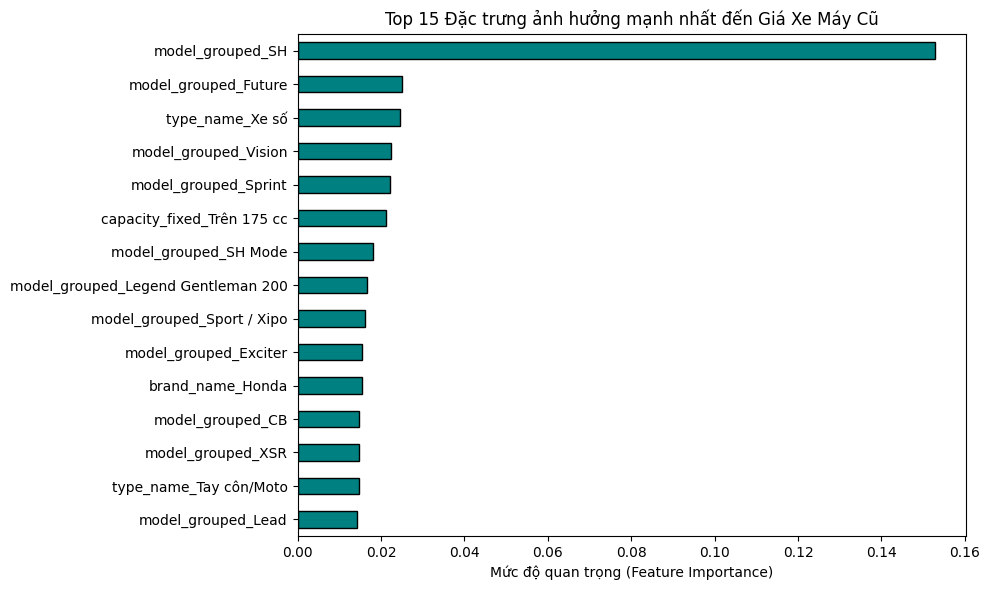

In [19]:
xgb_step = best_pipeline.named_steps['model']
prep_step = best_pipeline.named_steps['preprocessor']

cat_encoded_names = prep_step.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_features).tolist()
all_feature_names = num_features + cat_encoded_names + flag_features

importances = pd.Series(xgb_step.feature_importances_, index=all_feature_names)
top_15_features = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
top_15_features.plot(kind='barh', color='teal', edgecolor='black')
plt.title('Top 15 Đặc trưng ảnh hưởng mạnh nhất đến Giá Xe Máy Cũ')
plt.xlabel('Mức độ quan trọng (Feature Importance)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

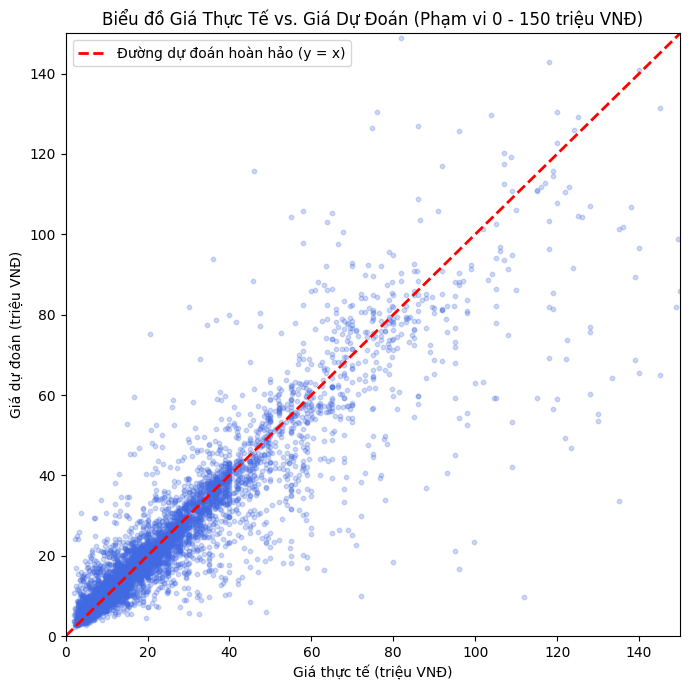

In [20]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test_real / 1e6, best_pred_vnd / 1e6, alpha=0.25, s=10, color='royalblue')
max_val = max(y_test_real.max(), best_pred_vnd.max()) / 1e6
plt.plot([0, max_val], [0, max_val], 'r--', lw=2, label='Đường dự đoán hoàn hảo (y = x)')
plt.xlim(0, 150)
plt.ylim(0, 150)
plt.xlabel('Giá thực tế (triệu VNĐ)')
plt.ylabel('Giá dự đoán (triệu VNĐ)')
plt.title('Biểu đồ Giá Thực Tế vs. Giá Dự Đoán (Phạm vi 0 - 150 triệu VNĐ)')
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
error_df = test_df[['list_id', 'subject', 'brand_name', 'model_grouped', 'regdate', 'tuoi_xe', 'mileage_v2', 'price']].copy()
error_df['price_pred'] = best_pred_vnd
error_df['abs_error'] = (error_df['price'] - error_df['price_pred']).abs()
error_df['pct_error'] = (error_df['abs_error'] / error_df['price']) * 100

print("--- Top 15 tin đăng có sai số tuyệt đối (VNĐ) lớn nhất ---")
top_15_errors = error_df.sort_values(by='abs_error', ascending=False).head(15)
display(top_15_errors.style.format({
    'mileage_v2': '{:,.0f}',
    'price': '{:,.0f}',
    'price_pred': '{:,.0f}',
    'abs_error': '{:,.0f}',
    'pct_error': '{:.1f}%'
}))

--- Top 15 tin đăng có sai số tuyệt đối (VNĐ) lớn nhất ---


,list_id,subject,brand_name,model_grouped,regdate,tuoi_xe,mileage_v2,price,price_pred,abs_error,pct_error
15967,135037582,Indian Chieftian 2014 Đỏ 2826 km HQCN,Harley Davidson,Khác,2014,12,"2,826","495,000,000","94,476,080","400,523,920",80.9%
18094,134041242,Ducati Diavel 1260 S 2019 - Bản TOP,Ducati,Khác,2019,7,"4,268","439,000,000","146,694,608","292,305,392",66.6%
26327,133004967,Vespa 946 up Red odo 5000 km chất xe như mới,Piaggio,Khác,2013,13,"5,000","340,000,000","64,428,320","275,571,680",81.1%
13915,134918205,Triumph Speed Triple 2021 Đen 8500km,Triumph,Khác,2021,5,"8,500","305,000,000","33,891,684","271,108,316",88.9%
17723,134342530,Bán xe Triumph Tiger 900,Triumph,Khác,2025,1,"4,700","389,000,000","139,865,952","249,134,048",64.0%
3112,134489265,Ducati Multistrada 1260S 2019 Đỏ 36000 km,Ducati,Khác,2019,7,"36,000","325,000,000","88,567,400","236,432,600",72.7%
17816,131991286,Harley-Davidson Low Rider 107Ci 2019,Harley Davidson,Khác,2019,7,8,"395,000,000","246,156,448","148,843,552",37.7%
16525,133866099,Kawasaki Z1000 2019 Đen 18.000 km,Kawasaki,Khác,2019,7,"18,000","249,000,000","106,468,560","142,531,440",57.2%
2980,134574273,Triumph Scrambler 1200X 2024 Bạc 11000 km,Triumph,Khác,2024,2,"11,000","439,000,000","298,373,568","140,626,432",32.0%
23513,134069755,SH 150 số 109 cuối 2014 nhập mới 95% 43C1-446.46,Honda,SH,2014,12,"28,000","180,000,000","40,470,144","139,529,856",77.5%


## 10. Đóng Gói Mô Hình (`models/model.pkl`) & Xuất `requirements.txt`
Thống nhất đường dẫn lưu và nạp model tại `models/model.pkl` để đồng bộ với cấu trúc bàn giao trong repository.

In [22]:
os.makedirs('models', exist_ok=True)
MODEL_SAVE_PATH = 'models/model.pkl'

joblib.dump(best_pipeline, MODEL_SAVE_PATH)
print(f"Đã lưu thành công pipeline vào: {MODEL_SAVE_PATH}")

# Kiểm tra đọc lại từ đúng đường dẫn models/model.pkl
loaded_pipeline = joblib.load(MODEL_SAVE_PATH)
verify_preds = np.expm1(loaded_pipeline.predict(X_test.iloc[:5]))
print("Kiểm thử đọc lại models/model.pkl thành công! Dự đoán 5 mẫu đầu (VNĐ):")
for idx, (real_p, pred_p) in enumerate(zip(y_test_real[:5], verify_preds), 1):
    print(f"  Mẫu {idx}: Thực tế = {real_p:,.0f} đ | Dự đoán = {pred_p:,.0f} đ")

Đã lưu thành công pipeline vào: models/model.pkl
Kiểm thử đọc lại models/model.pkl thành công! Dự đoán 5 mẫu đầu (VNĐ):
  Mẫu 1: Thực tế = 53,800,000 đ | Dự đoán = 63,790,032 đ
  Mẫu 2: Thực tế = 13,300,000 đ | Dự đoán = 31,051,502 đ
  Mẫu 3: Thực tế = 29,800,000 đ | Dự đoán = 28,714,932 đ
  Mẫu 4: Thực tế = 8,000,000 đ | Dự đoán = 9,817,696 đ
  Mẫu 5: Thực tế = 14,000,000 đ | Dự đoán = 10,424,962 đ


In [23]:
requirements_content = f"""numpy>=1.26.0,<2.0.0
pandas>=2.1.0,<2.3.0
matplotlib>=3.8.0
seaborn>=0.13.0
scikit-learn=={sklearn.__version__}
xgboost>=2.0.0
lightgbm>=4.3.0
joblib>=1.3.0
streamlit>=1.32.0
"""

with open('requirements.txt', 'w', encoding='utf-8') as f:
    f.write(requirements_content)

print("Đã tạo file requirements.txt với nội dung:")
print(requirements_content)

Đã tạo file requirements.txt với nội dung:
numpy>=1.26.0,<2.0.0
pandas>=2.1.0,<2.3.0
matplotlib>=3.8.0
seaborn>=0.13.0
scikit-learn==1.6.1
xgboost>=2.0.0
lightgbm>=4.3.0
joblib>=1.3.0
streamlit>=1.32.0

